## Tony Grove - Temperature Reanalysis Data Extraction
This script is used develop methods for downloading and adjusting NLDAS Reanalysis temperature data. Tony Grove has multiple datasets to compare.

The goal is to adjust the reanalysis temperature data to match the observed max/min temperatures at the snotel site.

In [1]:
%matplotlib ipympl
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from gdriver.gdriver import get_file, get_credentials, getCSVtoPandas
from io import StringIO
from buildforcing.downscale import downscaleTair

#### Load SNOTEL data
Tony Grove snotel data should be in file: bcqc_41.89000_-111.57000.txt

The snotel data is QC'd from raw daily measurements, which are going to correspond to the local timezone. 

In [2]:
# Load gdriver credentials
credentials = get_credentials()

PNNL Snotel Dataset Units:
- Daily Precip (in)
- temperatures (F)
- water year SWE (in)

In [3]:
# Download the txt file from Google Drive
rawfile = get_file('bcqc_41.89000_-111.57000.txt',creds=credentials)

# Read the txt file into a pandas dataframe. No header, separator is spaces
snotel_data = pd.read_csv(rawfile, delimiter=r'\s+', header=None, names=['Year', 'Month', 'Day', 'Precipitation', 'Max Temp', 'Min Temp', 'Avg Temp', 'Snow Water Equivalent'])

Downloading: 100%


In [ ]:
snotel_data.head()

Snotel data spans roughly fall 2009 to Sept 2021.

In [4]:
# convert Month, Day, Year to a datetime object and set as index
snotel_data['Date'] = pd.to_datetime(snotel_data[['Year', 'Month', 'Day']])
snotel_data.set_index('Date', inplace=True)

In [5]:
# Create new dataframe with only temperatures and convert to C
snotel_temps = snotel_data[['Max Temp', 'Min Temp', 'Avg Temp']].copy()
snotel_temps = snotel_temps.apply(lambda x: (x-32)*5/9)

### Load Reanalysis Data
Using NLDAS which has an hourly timestep and 1/8 degree resolution. For this development script, I will use the 2015/2016 water year since that was the second year the GAMUT station was running. I might want to assess a later year with the GAMUT EE08 sensor, but will wait for now.


In [6]:
# Define the base URL for the NLDAS Data Rods API
base_url = 'https://hydro1.gesdisc.eosdis.nasa.gov/daac-bin/access/timeseries.cgi'

# Define the parameters for the API request
params = {
    'variable': 'NLDAS2:NLDAS_FORA0125_H_v2.0:Tair',  # Example variable: 2-meter temperature
    'startDate': '2016-01-01T00',  # Start date in YYYY-MM-DDTHH format
    'endDate': '2016-01-15T00',    # End date in YYYY-MM-DDTHH format
    'location': 'GEOM:POINT(-111.57, 41.89)',  # Location as a point (longitude, latitude), note that the space in lat is important!!
    'type': 'asc2'  # Response format (e.g., asc2 for ASCII)
}

In [7]:
# Make the GET request to the API
response = requests.get(base_url, params=params)

# Check if the request was successful
if response.status_code == 200:
    # Print the response content
    nldas_csv = StringIO(response.text)
else:
    print(f"Error: {response.status_code}")

It took about 40sec to download about a year of data. By accident I only downloaded one day of data and it still took about 40sec, so it must be processing on the backend regardless of file size.

In [8]:
# Review the first few lines of the data to determine how many rows to skip for the header
sample_lines = nldas_csv.getvalue().split('\n')[:15]
for line in sample_lines:
    print(line)

Metadata for Requested Time Series:

prod_name=NLDAS_FORA0125_H_v2.0
param_short_name=Tair
param_name=2-meter above ground Temperature
unit=K
begin_time=2016-01-01T00
end_time=2016-01-15T00
lat= 41.9375
lon=-111.5625
Request_time=2025-03-17 19:58:25 GMT

Date&Time               Data
2016-01-01T00:00:00	256.76
2016-01-01T01:00:00	256.06


I reviewed the location shown in the metadata corresponding to the middle of the NLDAS grid cell. It is centered near the Franklin climate station and 1/8 degree looks like it covers all of Beaver Mountain.

In [9]:
# Based on the inspection, I should skip the first 12 rows of data
skip_rows = 12

# Load the data into a Pandas DataFrame, skipping the necessary rows
nldas_csv.seek(0)  # Reset the StringIO object to the beginning
nldas_data = pd.read_csv(nldas_csv, delimiter=r'\s+', skiprows=skip_rows, index_col=0, parse_dates=True)

In [ ]:
# Convert the temperature from Kelvin to Celsius
nldas_data['Tair'] = nldas_data['Data'] - 273.15

### Download GAMUT temperature data
Note that I found some weird duplicates in the DateTimeUTC column, so will use the LocalDateTime column for indexing

In [10]:
# Get the ST110 data
gamut_data = getCSVtoPandas('TonyGrove/LR_TG_C_AirTemp_ST110_Avg_SourceID_1_QC_1.csv',credentials,skiprows=56)

# Change index to DateTimeUTC
gamut_data['DateTime'] = pd.to_datetime(gamut_data['LocalDateTime'])
gamut_data = gamut_data.set_index('DateTime')

# Convert -9999 to NaN
gamut_data = gamut_data.replace(-9999, np.nan)

Download 100.


### Timezone Adjustment
The snotel data is daily, QC'd from daily values. It isn't clear what timezone the datalogger calculating the daily values is using... probably local?

The reanalysis data must be in UTC since the input date range could be applied to anywhere in the model domain.

I will convert timezones to MST and make some comparisons.

In [11]:
nldas_data.index = nldas_data.index.tz_localize('UTC')
gamut_data.index = gamut_data.index.tz_localize('America/Phoenix')

In [ ]:
# Convert to America/Phoenix timezone since this is essentially MST with no daylight savings
nldas_data = nldas_data.tz_convert('America/Phoenix')

In [12]:
# Check for duplicate indices
gamut_data_dups = gamut_data[gamut_data.index.duplicated()]

### Compare temperatures between reanalysis and observed

In [ ]:
# Compare Dec 2015
fig, ax = plt.subplots(figsize=(15, 6))
nldas_data['Tair']['2015-12'].plot(ax=ax, label='NLDAS', color='g')
gamut_data['AirTemp_ST110_Avg']['2015-12'].plot(ax=ax, label='ST110', color='b')
snotel_temps['Max Temp']['2015-12'].plot(ax=ax, style='r*', label='SNOTEL')
snotel_temps['Min Temp']['2015-12'].plot(ax=ax, style='b*', label=None)

Max and min snotel values appear to be close to GAMUT data, so "stretching" the reanalysis data to fit will improve it quite a bit.

### Daily averages

In [ ]:
# Resample NLDAS and ST110 to daily using means
nldas_daily = nldas_data['Tair'].resample('D').mean()
gamut_daily = gamut_data.loc['2015-10-01':'2016-06-01','AirTemp_ST110_Avg'].resample('D').mean()

In [ ]:
# Plot mean daily values to compare
fig, ax = plt.subplots(figsize=(15, 6))
nldas_daily['2015-12'].plot(ax=ax, label='NLDAS', style='g*')
gamut_daily['2015-12'].plot(ax=ax, label='ST110', style='b*')
snotel_data['Avg Temp C']['2015-12'].plot(ax=ax, style='r*', label='SNOTEL')


As expected, GAMUT daily means are closer to SNOTEL daily means than the reanalysis, which is generally colder. That makes sense since the grid cell location is further north and overall elevation likely higher than TG elevation.

### Downscaling of NLDAS
Uses the buildforcing package

In [13]:
nldas_df = pd.DataFrame(nldas_data)

In [14]:
snotel_data = snotel_data.tz_localize('America/Phoenix')

In [16]:
# Verify the 2016-01-01 to 2016-01-15 data is present
snotel_data['Max Temp']['2016-01-01':'2016-01-15']

Date
2016-01-01 00:00:00-07:00    27.29
2016-01-02 00:00:00-07:00    36.56
2016-01-03 00:00:00-07:00    44.80
2016-01-04 00:00:00-07:00    42.74
2016-01-05 00:00:00-07:00    36.56
2016-01-06 00:00:00-07:00    38.62
2016-01-07 00:00:00-07:00    38.62
2016-01-08 00:00:00-07:00    34.50
2016-01-09 00:00:00-07:00    29.35
2016-01-10 00:00:00-07:00    32.44
2016-01-11 00:00:00-07:00    30.38
2016-01-12 00:00:00-07:00    36.56
2016-01-13 00:00:00-07:00    41.71
2016-01-14 00:00:00-07:00    29.35
2016-01-15 00:00:00-07:00    30.38
Name: Max Temp, dtype: float64

In [17]:
nldas_df['Tair_downscaled'] = downscaleTair(nldas_df['Data'], snotel_data['Max Temp'], snotel_data['Min Temp'])

In [19]:
# Create a column in C
nldas_df['Tair_C'] = nldas_df['Data'] - 273.15
nldas_df['Tair_C_downscaled'] = nldas_df['Tair_downscaled'] - 273.15

<Axes: xlabel='DateTime'>

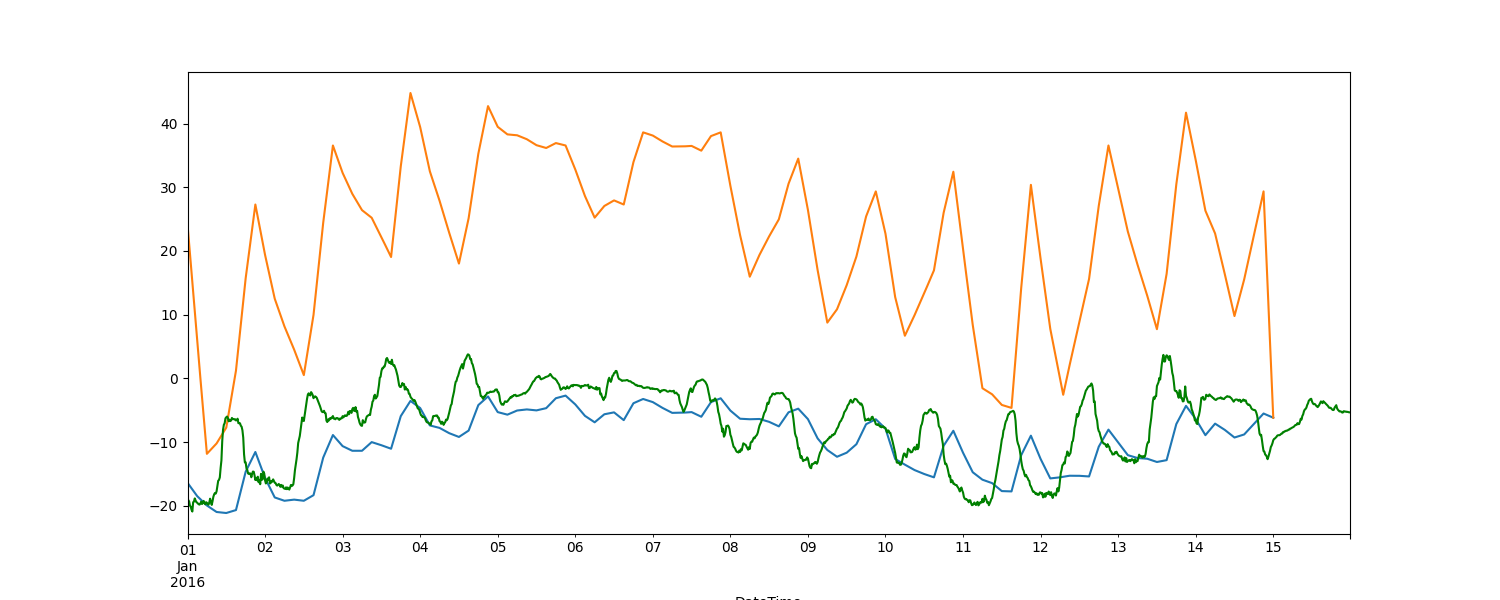

In [20]:
# Plot the original and shifted temperatures
fig, ax = plt.subplots(figsize=(15, 6))
nldas_df['Tair_C'].plot(ax=ax, label='NLDAS', style='b')
nldas_df['Tair_C_downscaled'].plot(ax=ax, label='NLDAS', style='r--')
gamut_data['AirTemp_ST110_Avg']['2016-01-01':'2016-01-15'].plot(ax=ax, label='ST110', color='g')

In [ ]:
# Get the daily max and min values for Dec 2015
nldas_daily_max = nldas_data.loc['2015-12','Tair'].resample('D').max()
nldas_daily_min = nldas_data.loc['2015-12','Tair'].resample('D').min()

In [ ]:
# Compute the difference between the max and min values and snotel max and min
nldas_daily_max_diff = snotel_temps.loc['2015-12','Max Temp'] - nldas_daily_max
nldas_daily_min_diff = snotel_temps.loc['2015-12','Min Temp'] - nldas_daily_min

In [ ]:
snotel_data_WY2016 = snotel_data.loc['2015-10-01':'2016-06-01']
nldas_data_WY2016 = nldas_daily.loc['2015-10-01':'2016-06-01'].tz_localize(None)  # Remove timezone for comparison
gamut_data_WY2016 = gamut_daily.tz_localize(None)  # Remove timezone for comparison

In [ ]:
# Calculate offset between NLDAS and TG data
nldas_offset = snotel_data_WY2016['Avg Temp C'] - nldas_data_WY2016
gamut_offset = snotel_data_WY2016['Avg Temp C'] - gamut_data_WY2016
print(nldas_offset.describe())
print(gamut_offset.describe())

In [ ]:
nldas_data['Tair_corrected'] = nldas_data['Tair'] + mean_offset

In [ ]:
axs2 = nldas_data['Tair_corrected'].plot(title='NLDAS 2-meter Temperature', xlabel='Date', ylabel='Temperature (°C)')
snotel_data['Avg Temp']['2009-10-01':'2010-10-01'].plot(ax=axs2, style='r*')